# 05 · H1: the frozen round map, and its per-step form

**Why.** H1 says training self-tunes to the federated edge of the frozen round map
`A = Σ pᵢ (I − ηHᵢ)ᴷ`, `T = η_s (I − A)` (here η_s = 1, so `T = I − A`).

A perturbation is multiplied each round by `1 − τ` along each eigenvector of T. So the **growth per round** is
`g = max |1 − τ|` over the extreme eigenvalues (τ_min, τ_max). Stable ⇔ g < 1 (flat directions sit at g ≈ 1).

Because a round is K local steps, the **per-step growth** is `g^(1/K)`. Writing it like plain GD's factor `|1 − ηλ| = 2c − 1` gives a per-step edge index

`c_eff = (1 + g^(1/K)) / 2`   (1 = edge, same scale as sharpness·η/2).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # repo root when run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eosfl import obs
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def edge_line(ax, y=1.0):
    ax.axhline(y, color="k", lw=0.8)

In [2]:
runs = obs.load_runs("fedavg_main"); traj = obs.load_traj("fedavg_main")
AL = {np.inf: "α=∞ (IID)", 1.0: "α=1", 0.1: "α=0.1"}
has = runs.dropna(subset=["eq_tau_max"])
print(len(has), "runs with the frozen round map (K=20, η=0.04 was run without it)")

55 runs with the frozen round map (K=20, η=0.04 was run without it)


## 1. The raw τ_max/2 zigzags with K

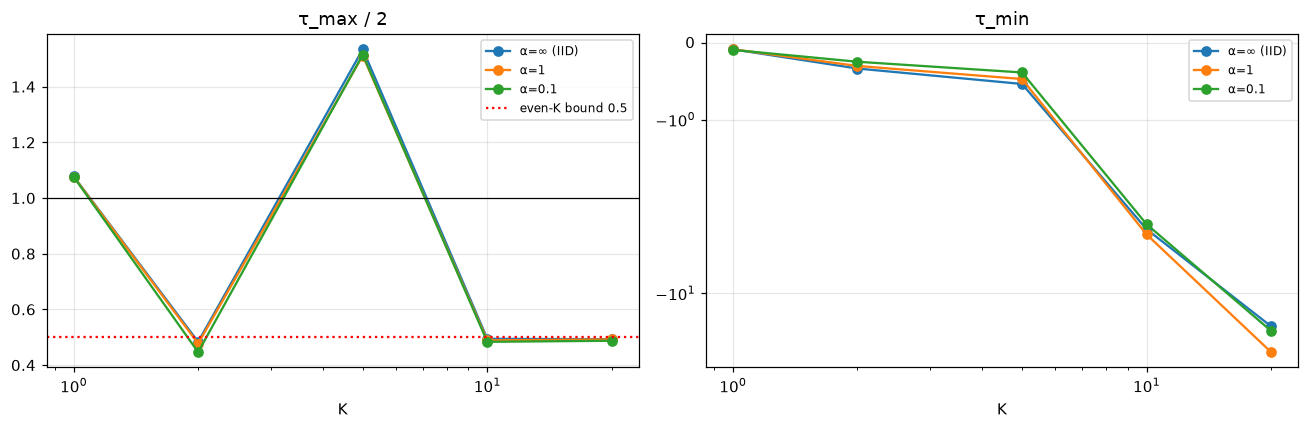

eq_tau_min               eq_tau_max            
alpha              0.1    1.0    inf        0.1   1.0   inf
local_steps                                                
1                -0.09  -0.09  -0.09       2.15  2.15  2.16
2                -0.25  -0.30  -0.34       0.89  0.95  0.97
5                -0.39  -0.47  -0.54       3.03  3.02  3.07
10               -3.17  -3.75  -3.44       0.97  0.98  0.99
20              -18.66 -26.54 -17.29       0.97  0.98  0.99

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for a in [np.inf, 1.0, 0.1]:
    g = has[has.alpha == a].groupby("local_steps")
    axes[0].plot(g.eq_tau_max.mean().index, g.eq_tau_max.mean() / 2, "o-", label=AL[a])
    axes[1].plot(g.eq_tau_min.mean().index, g.eq_tau_min.mean(), "o-", label=AL[a])
axes[0].axhline(0.5, color="r", ls=":", label="even-K bound 0.5"); edge_line(axes[0])
axes[0].set_title("τ_max / 2"); axes[1].set_title("τ_min"); axes[1].set_yscale("symlog")
for ax in axes: ax.set_xscale("log"); ax.set_xlabel("K"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(has.groupby(["alpha", "local_steps"])[["eq_tau_min", "eq_tau_max"]].mean().unstack(0).round(2))

## 2. Growth per round: the frozen map says 'unstable' at every K > 1

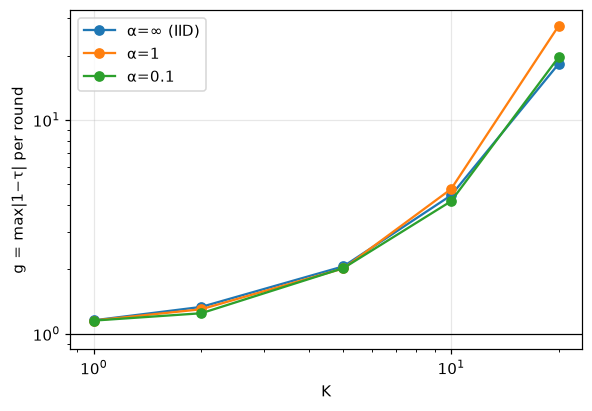

runs that diverged: 0 | max final train loss: 0.119


In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
for a in [np.inf, 1.0, 0.1]:
    g = has[has.alpha == a].groupby("local_steps").eq_g_frozen.mean()
    ax.plot(g.index, g, "o-", label=AL[a])
ax.axhline(1, color="k", lw=0.8); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("K"); ax.set_ylabel("g = max|1−τ| per round"); ax.legend(); plt.show()
print("runs that diverged:", int((runs.status == "diverged").sum()) if "status" in runs else "n/a",
      "| max final train loss:", round(runs.final_train_loss.max(), 3))

## 3. Per step, the growth is the same everywhere: c_eff

In [5]:
def tab(col):
    t = has.groupby(["alpha", "local_steps"])[col].mean().unstack()
    t.index = [AL[a] for a in t.index]; return t.loc[[AL[a] for a in [np.inf, 1.0, 0.1]]].round(3)
print("c_eff (per-step edge index of the frozen round map)"); display(tab("eq_ceff_frozen"))
print("for reference, global sharpness·η/2"); display(tab("eq_sharp_norm"))
print("and max client sharpness·η/2"); display(tab("eq_client_norm"))

c_eff (per-step edge index of the frozen round map)


local_steps,1,2,5,10,20
α=∞ (IID),1.078,1.078,1.078,1.079,1.078
α=1,1.077,1.071,1.075,1.084,1.089
α=0.1,1.077,1.059,1.076,1.076,1.080


for reference, global sharpness·η/2


local_steps,1,2,5,10,20
α=∞ (IID),1.079,1.063,1.062,1.061,1.058
α=1,1.077,1.051,1.053,1.049,1.047
α=0.1,1.077,1.006,0.993,0.978,0.982


and max client sharpness·η/2


local_steps,1,2,5,10,20
α=∞ (IID),1.150,1.129,1.120,1.112,1.104
α=1,1.238,1.188,1.166,1.151,1.146
α=0.1,1.459,1.235,1.183,1.148,1.128


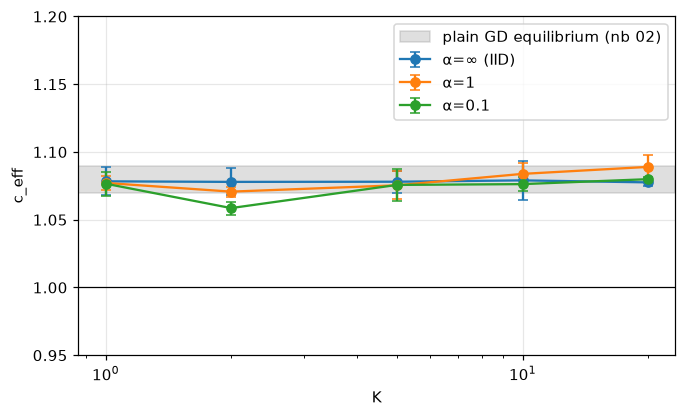

c_eff over all K>1 runs: mean 1.076, std 0.010, range [1.054, 1.099]


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for a in [np.inf, 1.0, 0.1]:
    g = has[has.alpha == a].groupby("local_steps").eq_ceff_frozen.agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, label=AL[a])
ax.axhspan(1.07, 1.09, color="grey", alpha=0.25, label="plain GD equilibrium (nb 02)")
edge_line(ax); ax.set_xscale("log"); ax.set_xlabel("K"); ax.set_ylabel("c_eff"); ax.set_ylim(0.95, 1.2); ax.legend()
plt.show()
k = has[has.local_steps > 1].eq_ceff_frozen
print(f"c_eff over all K>1 runs: mean {k.mean():.3f}, std {k.std():.3f}, range [{k.min():.3f}, {k.max():.3f}]")

## 4. Robustness of the per-step number

In [7]:
sep = np.maximum((1 - has.eq_tau_min).abs(), (1 - has.eq_tau_max).abs())
has = has.assign(ceff_sep=(1 + sep ** (1 / has.local_steps)) / 2)
print("max |row-wise − separate-medians| c_eff:", (has.eq_ceff_frozen - has.ceff_sep).abs().max().round(4))
display(has.groupby(["lr", "local_steps"]).eq_ceff_frozen.mean().unstack().round(3))
k1 = has[has.local_steps == 1]
print("K=1 identity check, max |c_eff − sharp_norm|:", (k1.eq_ceff_frozen - k1.eq_sharp_norm).abs().max().round(4))

max |row-wise − separate-medians| c_eff: 0.0012


local_steps,1,2,5,10,20
lr,,,,,
0.02,1.070,1.064,1.068,1.072,1.081
0.04,1.084,1.074,1.085,1.087,1.099


K=1 identity check, max |c_eff − sharp_norm|: 0.0038


## 5. c_eff over training (η = 0.02, seed 0)

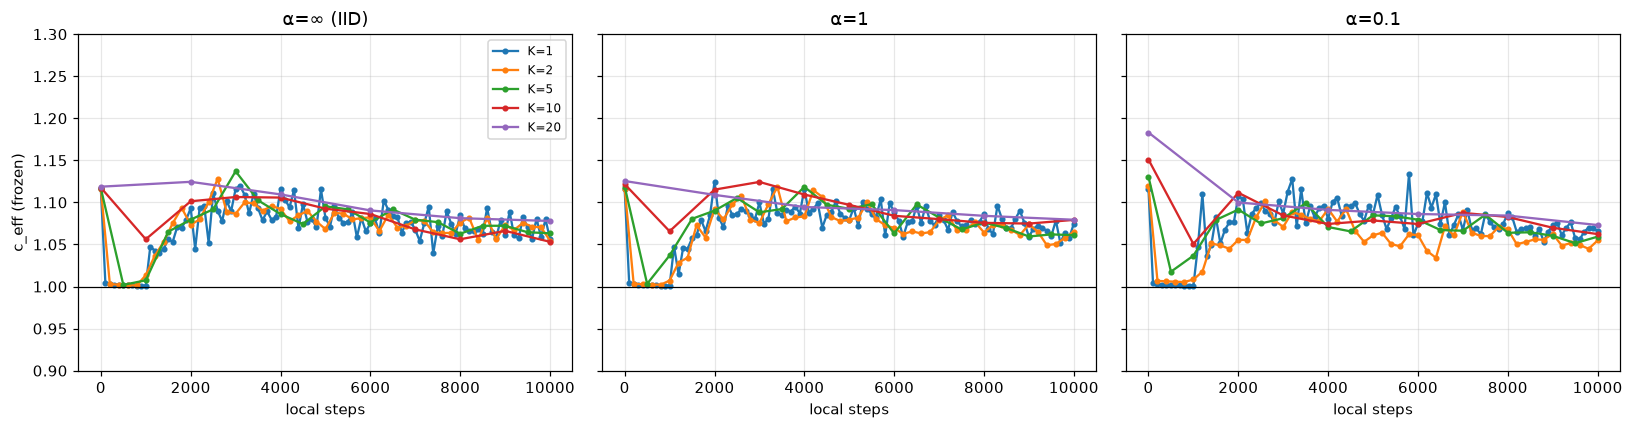

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, a in zip(axes, [np.inf, 1.0, 0.1]):
    for K, g in traj[(traj.alpha == a) & np.isclose(traj.lr, 0.02) & (traj.seed == 0)].groupby("local_steps"):
        r = g.dropna(subset=["ceff_frozen"])
        if len(r): ax.plot(r.steps, r.ceff_frozen, "o-", ms=3, label=f"K={K}")
    edge_line(ax); ax.set_title(AL[a]); ax.set_xlabel("local steps"); ax.set_ylim(0.9, 1.3)
axes[0].set_ylabel("c_eff (frozen)"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Conclusions

1. **H1 as stated fails.** The raw τ_max/2 is not ≈ 1: it zigzags with the parity of K, which is an artifact (even K caps it at 0.5), and the growth per round g grows quickly with K (≈18–27 at K = 20) while every run trains stably (sections 1, 2).
2. **Per local step, the frozen round map is at the same place everywhere.** c_eff ≈ 1.06–1.09 in all settings, the same band as plain GD's EoS (section 3). Reformulated H1: *FedAvg self-tunes so that the frozen round map's growth per local step equals GD's EoS overshoot.*
3. **It tracks η like plain GD.** c_eff is ≈1.06–1.08 at η = 0.02 and ≈1.07–1.10 at η = 0.04, the same η-dependence as the centralized runs (1.07 and 1.09) (section 4b).
4. **Why the raw version fails:** each local step overshoots by a GD-like ≈8%; the frozen map compounds that over K steps, so g grows like (1.15)ᴷ.

**Caveats.** K = 1 is obvious. Hessians are frozen at the round start. The pattern was found after looking at the data (2 seeds), so it is a hypothesis to test. Notebook 06 tests it with the path-linearized round map.